In [1]:
import matplotlib.pyplot as plt
import numpy as np
import time

In [2]:
#### CONSTANTES FÍSICAS 
## Vamos a trabajar en años
# T12 = 5730.0
# Lambda = np.log(2)/T12

T12 = np.log(2)
Lambda = np.log(2) / T12

n0 = 5*10**3 # número de núcleos a tiempo t=0

t = 5       # tiempo total que vamos a simular
dt = 0.05    # intervalo de tiempo
u = int(t/dt)  # número de intervalos
tiempos = np.arange(u + 1) * dt


# Posición del tiempo de vida media
pos_t12 = int(round(T12 / dt))

# Tiempo de referencia
t_ref = pos_t12 * dt

num_simulaciones = 500


plt.rcParams.update({
    "font.size": 13,
    "axes.titlesize": 15,
    "axes.labelsize": 13,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 10,
    "figure.figsize": (7.2, 4.8),
    "axes.grid": False,
    "lines.linewidth": 1.8
})



In [3]:
inicio = time.perf_counter()

M = np.zeros((num_simulaciones, u + 1))

q_step = np.exp(-Lambda * dt)

t_estimado = np.zeros(len(M))

tiempo_suma = 0

# Generador aleatorio
rng = np.random.default_rng(25)

for i in range(num_simulaciones):
    N = n0
    M[i, 0] = N

    for j in range(1, u + 1):
        N = rng.binomial(N, q_step)
        M[i, j] = N

    t_estimado[i] = -1/Lambda * np.log(M[i, pos_t12] / n0)
    tiempo_suma += t_estimado[i]

fin = time.perf_counter()

np.savetxt("Tiempo_estimado_para_cada_número_de_núcleos.txt", t_estimado)

tiempo_estimado = tiempo_suma / num_simulaciones
sigma_muestral = np.std(t_estimado, ddof=1)
sigma_muestral_relativo = sigma_muestral / tiempo_estimado

sigma_teórico = 1 / Lambda * np.sqrt((np.exp(t_ref * Lambda)-1) / n0)
sigma_teórico_relativo = sigma_teórico / t_ref

print(f"Tiempo de ejecución: {fin - inicio} segundos")
print(f"Tiempo de vida media de referencia: {t_ref} +- {sigma_teórico} años")
print(f"Tiempo estimado: {tiempo_estimado} +- {sigma_muestral} años")
print(f"Sigma teórico relativo: {sigma_teórico_relativo}")
print(f"Sigma muestral relativo: {sigma_muestral_relativo}")



Tiempo de ejecución: 0.05989316100021824 segundos
Tiempo de vida media de referencia: 0.7000000000000001 +- 0.014239049880314884 años
Tiempo estimado: 0.7005813735024606 +- 0.014049825069543885 años
Sigma teórico relativo: 0.02034149982902126
Sigma muestral relativo: 0.020054522716331593


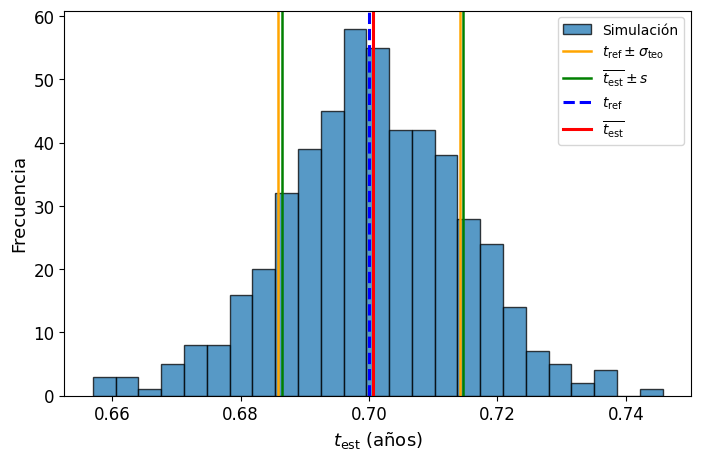

In [4]:

plt.hist(
    t_estimado,
    bins=25,
    edgecolor="black",
    alpha=0.75,
    label="Simulación"
)

# Intervalo teórico: t_ref ± sigma_teórico
plt.axvline(
    t_ref - sigma_teórico,
    color="orange",
    linestyle="-",
    linewidth=1.8,
    label=r"$t_{\mathrm{ref}}\pm\sigma_{\mathrm{teo}}$"
)

plt.axvline(
    t_ref + sigma_teórico,
    color="orange",
    linestyle="-",
    linewidth=1.8
)

# Intervalo muestral: media ± s
plt.axvline(
    tiempo_estimado - sigma_muestral,
    color="green",
    linestyle="-",
    linewidth=1.8,
    label=r"$\overline{t_{\mathrm{est}}}\pm s$"
)

plt.axvline(
    tiempo_estimado + sigma_muestral,
    color="green",
    linestyle="-",
    linewidth=1.8
)

# Tiempo de referencia
plt.axvline(
    t_ref,
    color="blue",
    linestyle="--",
    linewidth=2.2,
    label=r"$t_{\mathrm{ref}}$"
)

# Media muestral del tiempo estimado
plt.axvline(
    tiempo_estimado,
    color="red",
    linestyle="-",
    linewidth=2.2,
    label=r"$\overline{t_{\mathrm{est}}}$"
)

plt.xlabel(r"$t_{\mathrm{est}}$ (años)")
plt.ylabel("Frecuencia")
plt.legend()
plt.tight_layout()
plt.savefig("histograma_tiempo_estimado.png", dpi=300, bbox_inches="tight")
plt.show()